# Avaliação do classificador de intenções

Este notebook reproduz a bancada de avaliação do classificador de intenções (*feature* F21) sobre o conjunto de teste, e confere o resultado com os números publicados na seção **5.4.11 do [Projeto.md](../../../docs/Projeto.md)**.

- **Modelo avaliado:** o artefato versionado em `src/middleware/dados/classificador.joblib`, o mesmo que o middleware carrega em produção (ensemble de TF-IDF com `intfloat/multilingual-e5-large`, descrito em 5.9.1). Nada é treinado aqui.
- **Conjunto de teste:** 431 enunciados que não participaram do ajuste nem da calibração: os 364 da partição `dev` do corpus sintético e os 67 do CSV do catálogo (5.4.11.1).
- **Métricas:** todas vêm das funções de `app/pipeline/intencao/avaliacao.py`, as mesmas do comando `python -m app.pipeline.intencao.avaliacao`. O notebook não reimplementa nenhuma: ele as chama, mostra o que o relatório em texto não mostra (a matriz de confusão inteira e as métricas das 28 classes) e confere cada número com o documento.
- **Fora do escopo:** a comparação entre as sete configurações da F22 (5.4.11.7), que retreina cada uma do zero. Ela continua no comando `python -m app.pipeline.intencao.avaliacao --f22`.

Como executar está em [README.md](README.md).

## 1. Ambiente

O encoder do e5 é lido do cache do Hugging Face, na revisão fixada em `modelo.py`: com o cache pronto, a execução não usa rede. Os avisos de versão do scikit-learn são capturados e resumidos na tabela, em vez de despejados na saída.

In [1]:
import os
import warnings

# Sem rede e sem barras de progresso: o e5 já está no cache (ver README.md).
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("TQDM_DISABLE", "1")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import sys
from pathlib import Path

# O kernel abre na pasta do notebook; os imports `app.*` partem de src/middleware.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

In [3]:
import hashlib
import platform
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentence_transformers
import sklearn
from sklearn.exceptions import InconsistentVersionWarning

from app.pipeline.intencao import avaliacao, catalogo, treino
from app.pipeline.intencao.catalogo import Categoria
from app.pipeline.intencao.dados import carregar_teste
from app.pipeline.intencao.modelo import MODELO_EMBEDDINGS, REVISAO_EMBEDDINGS

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 40)

In [4]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", InconsistentVersionWarning)
    artefato = treino.carregar()

versao_gravada = sorted(
    {
        aviso.message.original_sklearn_version
        for aviso in avisos
        if isinstance(aviso.message, InconsistentVersionWarning)
    }
) or [sklearn.__version__]

def git(*argumentos: str) -> str:
    return subprocess.run(
        ["git", *argumentos], capture_output=True, text=True, cwd=RAIZ, check=False
    ).stdout.strip()


commit = git("rev-parse", "--short", "HEAD")
if commit and git("status", "--porcelain", "--", "app", "dados"):
    commit += " (com alterações locais em app/ ou dados/)"
conteudo = treino.CAMINHO_MODELO.read_bytes()

pd.Series(
    {
        "Commit do código avaliado": commit or "fora de um repositório git",
        "Python": platform.python_version(),
        "scikit-learn instalado": sklearn.__version__,
        "scikit-learn que gravou o artefato": ", ".join(versao_gravada),
        "sentence-transformers": sentence_transformers.__version__,
        "Encoder": f"{MODELO_EMBEDDINGS} @ {REVISAO_EMBEDDINGS[:7]}",
        "Artefato": "src/middleware/"
        + treino.CAMINHO_MODELO.relative_to(treino.CAMINHO_MODELO.parents[1]).as_posix(),
        "SHA-256 do artefato": hashlib.sha256(conteudo).hexdigest()[:16] + "…",
        "Tamanho do artefato": f"{len(conteudo) / 1_000_000:.2f} MB",
        "Configuração": artefato.configuracao.get("nome"),
        "Treinado em": artefato.treinado_em,
        "Enunciados de treino": artefato.total_treino,
        "Classes": len(artefato.classes),
        "Limiares calibrados": len(artefato.limiares),
    },
    name="valor",
).to_frame()

,valor
Commit do código avaliado,03a9a7e
Python,3.14.5
scikit-learn instalado,1.9.1
scikit-learn que gravou o artefato,1.9.0
sentence-transformers,6.1.0
Encoder,intfloat/multilingual-e5-large @ 3d7cfbd
Artefato,src/middleware/dados/classificador.joblib
SHA-256 do artefato,2f3b2f753109ab25…
Tamanho do artefato,3.95 MB
Configuração,ensemble-tfidf-e5-large


A faixa do scikit-learn no `pyproject.toml` está travada em `>=1.9,<1.10`, a *minor* que gravou o artefato (5.9.3). Um *patch* diferente dentro dela só emite o aviso resumido acima, e a conferência da seção 9 mostra que o resultado não muda.

## 2. Conjunto de teste

In [5]:
teste = carregar_teste()

composicao = (
    pd.DataFrame(
        {
            "origem": [e.origem.value for e in teste],
            "texto": ["ruidoso" if e.e_ruidoso else "canônico" for e in teste],
        }
    )
    .value_counts()
    .unstack(fill_value=0)
)
composicao["total"] = composicao.sum(axis=1)
composicao.loc["total"] = composicao.sum()
print(f"{len(teste)} enunciados, {len({e.intencao_id for e in teste})} classes")
composicao

431 enunciados, 28 classes


texto,ruidoso,canônico,total
origem,,,
sintetico,168,196,364
catalogo,0,67,67
total,168,263,431


O CSV do catálogo não tem coluna de variação, e por isso todos os seus 67 enunciados contam como canônicos: são os 263 canônicos e 168 ruidosos de 5.4.11.3.

## 3. Classificador puro contra as metas

Leitura sem os limiares de rejeição, como em 5.4.11.2: mede o modelo, e não o sistema. A primeira chamada carrega o encoder de cerca de 2 GB, o que leva perto de um minuto em CPU.

In [6]:
modelo = artefato.pipeline
resultado = avaliacao.avaliar(modelo, teste, "agregado")

metas = pd.DataFrame(
    [
        {
            "indicador": meta.nome,
            "meta": meta.alvo,
            "medido": round(meta.medido, 3),
            "medido (exato)": meta.medido,
            "situação": ("atingida" if meta.atingida else "abaixo")
            + ("" if meta.pactuada else " (não pactuada)"),
        }
        for meta in avaliacao.verificar_metas(resultado)
    ]
).set_index("indicador")
print(f"acurácia = {resultado.acuracia:.3f} · macro-F1 = {resultado.macro_f1:.3f}")
metas

acurácia = 0.856 · macro-F1 = 0.851


,meta,medido,medido (exato),situação
indicador,,,,
acurácia (O5/RNF03),0.85,0.856,0.856148,atingida
macro-F1,0.80,0.851,0.851063,atingida
recall em fora_de_escopo,0.90,0.905,0.904762,atingida
precisão média nas transações,0.90,0.900,0.899812,abaixo
recall em tentativa_injecao,0.90,0.857,0.857143,abaixo (não pactuada)


A precisão média nas transações merece uma linha: o relatório em texto a marca como **abaixo** da meta e a 5.4.11.2 como **no limite**. As duas leituras descrevem o mesmo valor, que arredonda para 0,900 e fica abaixo de 0,90 só a partir da quarta casa, como mostra a coluna exata. A meta é cumprida com os limiares aplicados (seção 7).

## 4. Os três recortes

Corpus sintético e CSV do catálogo são reportados separados, além do agregado, e o texto ruidoso separado do canônico (5.4.11.3 e `TNF-RNF03-03`/`04`).

In [7]:
recortes = {**avaliacao.por_origem(modelo, teste), **{
    f"texto {nome}": r for nome, r in avaliacao.por_ruido(modelo, teste).items()
}}
pd.DataFrame(
    [
        {"recorte": nome, "casos": r.total, "acurácia": r.acuracia, "macro-F1": r.macro_f1}
        for nome, r in recortes.items()
    ]
).set_index("recorte").round(3)

,casos,acurácia,macro-F1
recorte,,,
agregado,431,0.856,0.851
sintetico,364,0.832,0.824
catalogo,67,0.985,0.981
texto ruidoso,168,0.833,0.811
texto canonico,263,0.871,0.872


## 5. Métricas por intenção

As 28 classes, da pior para a melhor em F1. A 5.4.11.5 publica só as oito primeiras.

In [8]:
por_classe = pd.DataFrame(
    [
        {
            "intenção": m.intencao_id,
            "categoria": catalogo.obter(m.intencao_id).categoria.value,
            "precisão": m.precisao,
            "recall": m.recall,
            "F1": m.f1,
            "casos": m.suporte,
        }
        for m in resultado.por_intencao.values()
    ]
).sort_values(["F1", "intenção"]).set_index("intenção")
por_classe.round(2)

,categoria,precisão,recall,F1,casos
intenção,,,,,
consultar_pendencias,alerta,0.56,0.69,0.62,13
registrar_entrega_marco,transacao,0.69,0.64,0.67,14
consultar_marcos,consulta,0.91,0.56,0.69,18
consultar_problemas,consulta,0.82,0.64,0.72,14
gerar_relatorio_status,consulta,0.77,0.71,0.74,14
consultar_avanco,consulta,0.64,0.93,0.76,15
consultar_faturas_vencidas,consulta,0.79,0.73,0.76,15
gerar_relatorio_encerramento,consulta,0.83,0.71,0.77,14
atualizar_cronograma,transacao,0.81,0.76,0.79,17


## 6. Matriz de confusão

Linhas são o rótulo verdadeiro e colunas a intenção prevista, na ordem alfabética dos rótulos. A cor é a proporção da linha (o recall daquela classe na diagonal), e o número é a contagem de casos; células vazias são zero. É a matriz que o `TNF-RNF03-02` exige e que o relatório em texto resume nas confusões mais frequentes.

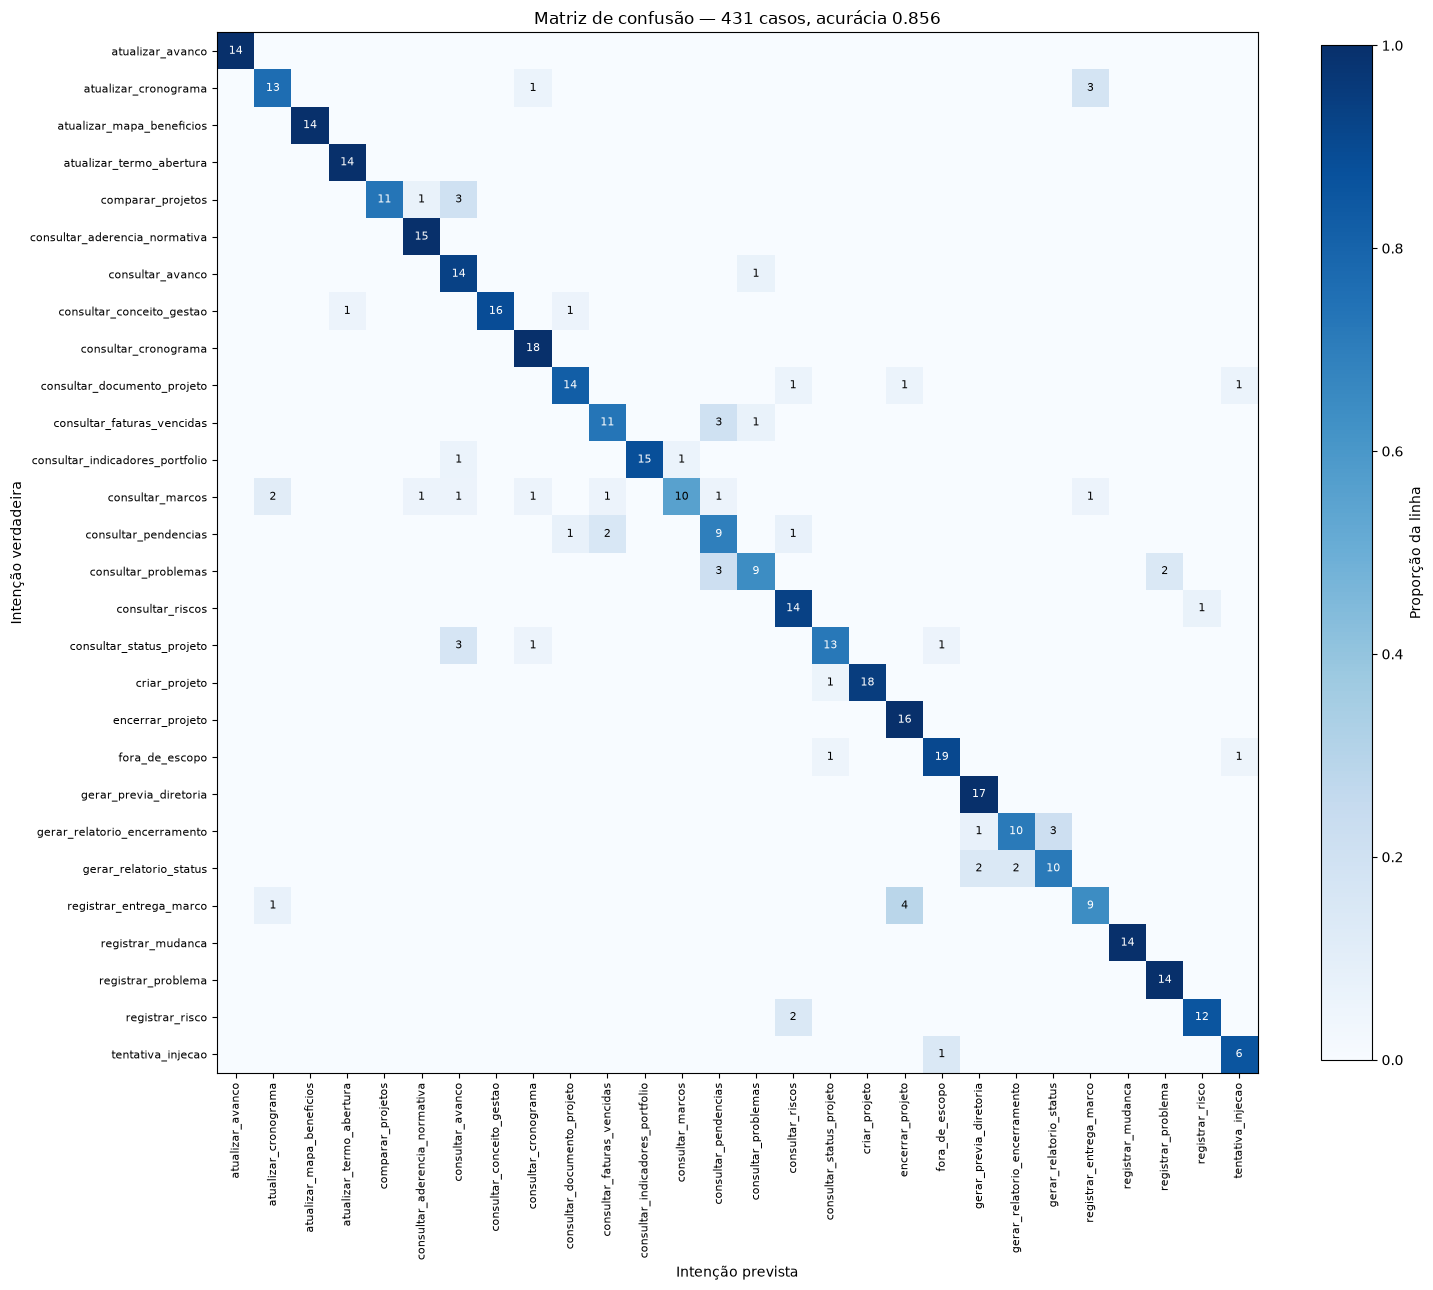

In [9]:
matriz = resultado.matriz
rotulos = resultado.rotulos
proporcao = matriz / matriz.sum(axis=1, keepdims=True)

figura, eixo = plt.subplots(figsize=(15, 13))
imagem = eixo.imshow(proporcao, cmap="Blues", vmin=0, vmax=1)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        if matriz[i, j]:
            cor = "white" if proporcao[i, j] > 0.6 else "black"
            eixo.text(j, i, int(matriz[i, j]), ha="center", va="center", fontsize=8, color=cor)
eixo.set_xticks(range(len(rotulos)), rotulos, rotation=90, fontsize=8)
eixo.set_yticks(range(len(rotulos)), rotulos, fontsize=8)
eixo.set_xlabel("Intenção prevista")
eixo.set_ylabel("Intenção verdadeira")
eixo.set_title(
    f"Matriz de confusão — {resultado.total} casos, acurácia {resultado.acuracia:.3f}"
)
figura.colorbar(imagem, ax=eixo, fraction=0.04, label="Proporção da linha")
figura.tight_layout()
plt.show()

A mesma matriz em tabela, para quem quiser ler uma célula sem contar quadrados:

In [10]:
pd.DataFrame(matriz, index=rotulos, columns=rotulos).rename_axis(
    index="verdadeira", columns="prevista"
)

prevista,atualizar_avanco,atualizar_cronograma,atualizar_mapa_beneficios,atualizar_termo_abertura,comparar_projetos,consultar_aderencia_normativa,consultar_avanco,consultar_conceito_gestao,consultar_cronograma,consultar_documento_projeto,consultar_faturas_vencidas,consultar_indicadores_portfolio,consultar_marcos,consultar_pendencias,consultar_problemas,consultar_riscos,consultar_status_projeto,criar_projeto,encerrar_projeto,fora_de_escopo,gerar_previa_diretoria,gerar_relatorio_encerramento,gerar_relatorio_status,registrar_entrega_marco,registrar_mudanca,registrar_problema,registrar_risco,tentativa_injecao
verdadeira,,,,,,,,,,,,,,,,,,,,,,,,,,,,
atualizar_avanco,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
atualizar_cronograma,0,13,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0
atualizar_mapa_beneficios,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
atualizar_termo_abertura,0,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
comparar_projetos,0,0,0,0,11,1,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
consultar_aderencia_normativa,0,0,0,0,0,15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
consultar_avanco,0,0,0,0,0,0,14,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
consultar_conceito_gestao,0,0,0,1,0,0,0,16,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
consultar_cronograma,0,0,0,0,0,0,0,0,18,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Confusões com três casos ou mais, do mais frequente ao menos frequente. As colunas seguem a tabela de 5.4.11.5: primeiro a intenção prevista ("classificado como"), depois o rótulo ("deveria ser").

In [11]:
confusoes = pd.DataFrame(
    [
        {"frequência": n, "classificado como": previsto, "deveria ser": verdadeiro}
        for verdadeiro, previsto, n in avaliacao.confusoes_mais_frequentes(resultado, minimo=3)
    ]
)
TRANSACOES = {i.id for i in catalogo.intencoes_por_categoria(Categoria.TRANSACAO)}
confusoes["categorias"] = [
    f"{catalogo.obter(p).categoria.value} ← {catalogo.obter(v).categoria.value}"
    for p, v in zip(confusoes["classificado como"], confusoes["deveria ser"])
]
confusoes["cruza leitura e transação"] = [
    (p in TRANSACOES) != (v in TRANSACOES)
    for p, v in zip(confusoes["classificado como"], confusoes["deveria ser"])
]
confusoes

,frequência,classificado como,deveria ser,categorias,cruza leitura e transação
0,4,encerrar_projeto,registrar_entrega_marco,transacao ← transacao,False
1,3,registrar_entrega_marco,atualizar_cronograma,transacao ← transacao,False
2,3,consultar_avanco,comparar_projetos,consulta ← consulta,False
3,3,consultar_pendencias,consultar_faturas_vencidas,alerta ← consulta,False
4,3,consultar_pendencias,consultar_problemas,alerta ← consulta,False
5,3,consultar_avanco,consultar_status_projeto,consulta ← consulta,False
6,3,gerar_relatorio_status,gerar_relatorio_encerramento,consulta ← consulta,False


## 7. Limiares calibrados

Com o limiar de cada intenção aplicado, como faz o orquestrador: a mensagem cuja classe mais provável não alcança o próprio limiar vira pedido de reformulação (5.4.11.4).

In [12]:
com_corte = avaliacao.avaliar_com_limiares(modelo, teste, artefato.limiares)
pd.Series(
    {
        "cobertura": round(com_corte.cobertura, 3),
        "acurácia entre as aceitas": round(com_corte.acuracia_aceitos, 3),
        "precisão média nas transações": round(
            com_corte.precisao_media(Categoria.TRANSACAO), 3
        ),
        "rejeitadas": f"{com_corte.rejeitados} de {com_corte.total}",
    },
    name="valor",
).to_frame()

,valor
cobertura,0.965
acurácia entre as aceitas,0.863
precisão média nas transações,0.905
rejeitadas,15 de 431


In [13]:
limiares = pd.Series(artefato.limiares, name="limiar").sort_values(ascending=False)
print(
    f"{(limiares == 0.05).sum()} dos {len(limiares)} limiares estão no piso de 0,05; "
    f"o maior é {limiares.max():.2f}."
)
limiares[limiares > 0.05].to_frame()

20 dos 28 limiares estão no piso de 0,05; o maior é 0.30.


,limiar
atualizar_cronograma,0.30
consultar_faturas_vencidas,0.30
consultar_status_projeto,0.20
consultar_marcos,0.20
registrar_entrega_marco,0.20
gerar_previa_diretoria,0.15
consultar_aderencia_normativa,0.15
comparar_projetos,0.10


### Leituras tomadas por transação

O erro caro é o que 5.4.8 temia: uma pergunta classificada como transação, que leva o agente a propor alteração de dado. Nenhuma das confusões frequentes é desse tipo, mas a matriz completa mostra casos isolados, abaixo do corte de três da tabela acima. A célula abaixo os lista e aplica a cada um o limiar da intenção prevista, com a mesma regra do orquestrador e de `avaliar_com_limiares`.

In [14]:
verdadeiros = np.array([e.intencao_id for e in teste])
probabilidades = modelo.predict_proba([e.texto for e in teste])
previstos = modelo.classes_[probabilidades.argmax(axis=1)].astype(str)
confiancas = probabilidades.max(axis=1)
cortes = np.array([artefato.limiares.get(p, 0.0) for p in previstos])
aceitos = confiancas >= cortes

leitura_como_transacao = pd.DataFrame(
    [
        {
            "enunciado": teste[i].texto,
            "deveria ser": verdadeiros[i],
            "classificado como": previstos[i],
            "confiança": round(float(confiancas[i]), 3),
            "limiar": cortes[i],
            "passa do limiar": bool(aceitos[i]),
        }
        for i in range(len(teste))
        if verdadeiros[i] not in TRANSACOES and previstos[i] in TRANSACOES
    ]
)
transacao_como_leitura = int(
    sum(v in TRANSACOES and p not in TRANSACOES for v, p in zip(verdadeiros, previstos))
)
print(
    f"{len(leitura_como_transacao)} leituras classificadas como transação, "
    f"{int(leitura_como_transacao['passa do limiar'].sum())} delas acima do limiar; "
    f"no sentido inverso, {transacao_como_leitura} transações classificadas como leitura."
)
leitura_como_transacao

8 leituras classificadas como transação, 6 delas acima do limiar; no sentido inverso, 4 transações classificadas como leitura.

,enunciado,deveria ser,classificado como,confiança,limiar,passa do limiar
0,qual o critério de termo de abertura segundo i...,consultar_conceito_gestao,atualizar_termo_abertura,0.371,0.05,True
1,consulta o termo de encerramento do sistema de...,consultar_documento_projeto,encerrar_projeto,0.214,0.05,True
2,o m3 já foi cumprido no terminal jabaquara,consultar_marcos,registrar_entrega_marco,0.209,0.20,True
3,Status do marco de liberação de área no Pátio ...,consultar_marcos,atualizar_cronograma,0.166,0.30,False
4,status do marco de liberação de área no projeto y,consultar_marcos,atualizar_cronograma,0.276,0.30,False
5,Lsita de ocorrências em andamento da Estação B...,consultar_problemas,registrar_problema,0.153,0.05,True
6,Lista de ocorrências reprovadas da Linha 6,consultar_problemas,registrar_problema,0.246,0.05,True
7,Qual a istuação do risco de ruptura de estoque...,consultar_riscos,registrar_risco,0.328,0.05,True


## 8. Curva de rejeição

Cobertura e acurácia entre as aceitas para um corte global de confiança, de 0,0 a 0,9 (5.4.11.6).

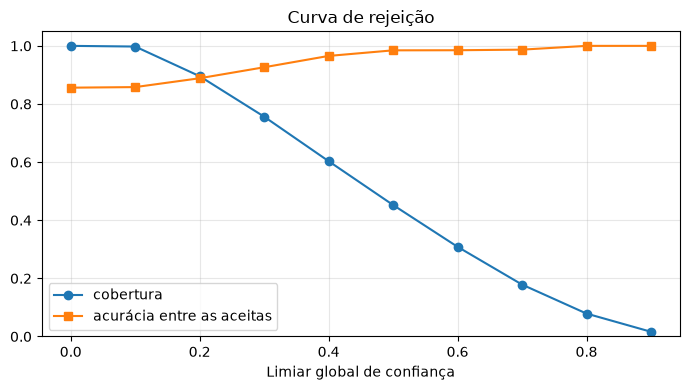

,cobertura,acurácia
limiar,,
0.0,1.000,0.856
0.1,0.998,0.858
0.2,0.896,0.889
0.3,0.756,0.926
0.4,0.603,0.965
0.5,0.452,0.985
0.6,0.309,0.985
0.7,0.179,0.987
0.8,0.079,1.000


In [15]:
pontos = avaliacao.curva_de_rejeicao(modelo, teste, tuple(round(0.1 * i, 1) for i in range(10)))
curva = pd.DataFrame(
    [
        {"limiar": p.limiar, "cobertura": p.cobertura, "acurácia": p.acuracia_aceitos}
        for p in pontos
    ]
).set_index("limiar")

figura, eixo = plt.subplots(figsize=(7, 4))
eixo.plot(curva.index, curva["cobertura"], marker="o", label="cobertura")
eixo.plot(curva.index, curva["acurácia"], marker="s", label="acurácia entre as aceitas")
eixo.set_xlabel("Limiar global de confiança")
eixo.set_ylim(0, 1.05)
eixo.grid(alpha=0.3)
eixo.legend()
eixo.set_title("Curva de rejeição")
figura.tight_layout()
plt.show()
curva.round(3)

## 9. Conferência com o Projeto.md

Cada número publicado em 5.4.11 ao lado do recalculado aqui. A tolerância é a do arredondamento do documento: meia unidade da última casa publicada (três casas nas métricas, duas nas tabelas por classe). Uma diferença maior interrompe o notebook.

In [16]:
# Valores transcritos de Projeto.md 5.4.11.2 a 5.4.11.6.
REFERENCIA_3_CASAS = {
    "acurácia": (0.856, resultado.acuracia),
    "macro-F1": (0.851, resultado.macro_f1),
    "recall em fora_de_escopo": (0.905, resultado.recall_de("fora_de_escopo")),
    "precisão média nas transações": (0.900, resultado.precisao_media(Categoria.TRANSACAO)),
    "recall em tentativa_injecao": (0.857, resultado.recall_de("tentativa_injecao")),
    "recorte sintético — acurácia": (0.832, recortes["sintetico"].acuracia),
    "recorte sintético — macro-F1": (0.824, recortes["sintetico"].macro_f1),
    "recorte catálogo — acurácia": (0.985, recortes["catalogo"].acuracia),
    "recorte catálogo — macro-F1": (0.981, recortes["catalogo"].macro_f1),
    "texto canônico — acurácia": (0.871, recortes["texto canonico"].acuracia),
    "texto ruidoso — acurácia": (0.833, recortes["texto ruidoso"].acuracia),
    "com limiares — cobertura": (0.965, com_corte.cobertura),
    "com limiares — acurácia entre as aceitas": (0.863, com_corte.acuracia_aceitos),
    "com limiares — precisão nas transações": (
        0.905,
        com_corte.precisao_media(Categoria.TRANSACAO),
    ),
}
CURVA_5_4_11_6 = {
    0.0: (1.000, 0.856), 0.1: (0.998, 0.858), 0.2: (0.896, 0.889), 0.3: (0.756, 0.926),
    0.4: (0.603, 0.965), 0.5: (0.452, 0.985), 0.6: (0.309, 0.985), 0.7: (0.179, 0.987),
    0.8: (0.079, 1.000), 0.9: (0.016, 1.000),
}
for limiar, (cobertura, acuracia) in CURVA_5_4_11_6.items():
    REFERENCIA_3_CASAS[f"curva {limiar:.1f} — cobertura"] = (cobertura, curva.loc[limiar, "cobertura"])
    REFERENCIA_3_CASAS[f"curva {limiar:.1f} — acurácia"] = (acuracia, curva.loc[limiar, "acurácia"])

PIORES_5_4_11_5 = {  # precisão, recall, F1, casos
    "consultar_pendencias": (0.56, 0.69, 0.62, 13),
    "registrar_entrega_marco": (0.69, 0.64, 0.67, 14),
    "consultar_marcos": (0.91, 0.56, 0.69, 18),
    "consultar_problemas": (0.82, 0.64, 0.72, 14),
    "gerar_relatorio_status": (0.77, 0.71, 0.74, 14),
    "consultar_avanco": (0.64, 0.93, 0.76, 15),
    "consultar_faturas_vencidas": (0.79, 0.73, 0.76, 15),
    "gerar_relatorio_encerramento": (0.83, 0.71, 0.77, 14),
}

linhas = [
    {"número": nome, "Projeto.md": publicado, "notebook": medido, "tolerância": 0.0005}
    for nome, (publicado, medido) in REFERENCIA_3_CASAS.items()
]
for intencao, (p, r, f1, casos) in PIORES_5_4_11_5.items():
    m = resultado.por_intencao[intencao]
    linhas += [
        {"número": f"{intencao} — precisão", "Projeto.md": p, "notebook": m.precisao, "tolerância": 0.005},
        {"número": f"{intencao} — recall", "Projeto.md": r, "notebook": m.recall, "tolerância": 0.005},
        {"número": f"{intencao} — F1", "Projeto.md": f1, "notebook": m.f1, "tolerância": 0.005},
        {"número": f"{intencao} — casos", "Projeto.md": casos, "notebook": m.suporte, "tolerância": 0},
    ]
conferencia = pd.DataFrame(linhas).set_index("número")
conferencia["diferença"] = conferencia["notebook"] - conferencia["Projeto.md"]
conferencia["confere"] = conferencia["diferença"].abs() <= conferencia["tolerância"]
print(f"{int(conferencia['confere'].sum())} de {len(conferencia)} números conferem.")
conferencia.round(4)

66 de 66 números conferem.


,Projeto.md,notebook,tolerância,diferença,confere
número,,,,,
acurácia,0.856,0.8561,0.0005,0.0001,True
macro-F1,0.851,0.8511,0.0005,0.0001,True
recall em fora_de_escopo,0.905,0.9048,0.0005,-0.0002,True
precisão média nas transações,0.900,0.8998,0.0005,-0.0002,True
recall em tentativa_injecao,0.857,0.8571,0.0005,0.0001,True
recorte sintético — acurácia,0.832,0.8324,0.0005,0.0004,True
recorte sintético — macro-F1,0.824,0.8245,0.0005,0.0005,True
recorte catálogo — acurácia,0.985,0.9851,0.0005,0.0001,True
recorte catálogo — macro-F1,0.981,0.9810,0.0005,-0.0000,True


In [17]:
divergentes = conferencia[~conferencia["confere"]]
assert divergentes.empty, f"Números divergentes da 5.4.11:\n{divergentes}"

CONFUSOES_5_4_11_5 = [
    (4, "encerrar_projeto", "registrar_entrega_marco"),
    (3, "registrar_entrega_marco", "atualizar_cronograma"),
    (3, "consultar_avanco", "comparar_projetos"),
    (3, "consultar_pendencias", "consultar_faturas_vencidas"),
    (3, "consultar_pendencias", "consultar_problemas"),
    (3, "consultar_avanco", "consultar_status_projeto"),
    (3, "gerar_relatorio_status", "gerar_relatorio_encerramento"),
]
medidas = [
    (linha["frequência"], linha["classificado como"], linha["deveria ser"])
    for _, linha in confusoes.iterrows()
]
assert sorted(medidas) == sorted(CONFUSOES_5_4_11_5), medidas
assert (com_corte.rejeitados, com_corte.total) == (15, 431)
assert (resultado.total, len(resultado.rotulos)) == (431, 28)
print("Todos os números e confusões da 5.4.11 foram reproduzidos.")

Todos os números e confusões da 5.4.11 foram reproduzidos.


## 10. Conclusão

O artefato versionado reproduz **todos** os números publicados em 5.4.11: as cinco metas, os três recortes, os quatro números com limiares, as oito piores classes, os dez pontos da curva de rejeição, as sete confusões mais frequentes e as 15 rejeições. São 66 de 66 números dentro do arredondamento do documento, e as confusões e rejeições conferidas por igualdade.

A matriz inteira acrescenta duas leituras que o documento não trazia:

- **As sete confusões frequentes não cruzam a fronteira entre leitura e transação**, como afirma 5.4.11.5, mas duas delas não ficam na mesma categoria do catálogo: `consultar_pendencias` é `alerta`, e as intenções que ela absorve são `consulta`. Todas as três são leituras.
- **Abaixo do corte de três casos, há 8 leituras classificadas como transação** (1,9% do teste), espalhadas por seis pares, e 6 delas passam do limiar da intenção prevista, porque oito das dez transações têm o limiar no piso de 0,05. É o erro que 5.4.8 temia: raro e disperso, mas não ausente. No sentido inverso são 4 casos.

Para reavaliar depois de um retreino, basta executar o notebook de novo. A seção 9 aponta qual número da 5.4.11 deixou de valer, e o documento precisa ser atualizado junto com o artefato.